# **Import Data**

In [ ]:
!pip install neuralforecast matplotlib pandas numpy scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from neuralforecast import NeuralForecast
from neuralforecast.models import TFT, Informer, NBEATS
from neuralforecast.losses.pytorch import MAE
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from sklearn.tree import DecisionTreeRegressor

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.2/263.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.4/287.4 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.5/849.5 kB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 64.1 MB/s eta 0:00:00


# **Load Dataset dan Pre Processing**

In [ ]:
df = pd.read_excel("THYAO_Saham.xlsx")
df

,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-01-04,12.386891,12.68,12.97,12.67,12.97,59948726
1,2021-01-05,12.289203,12.58,12.80,12.52,12.64,90905126
2,2021-01-06,12.386891,12.68,12.81,12.63,12.73,63226286
3,2021-01-07,12.386891,12.68,12.76,12.62,12.74,63579108
4,2021-01-08,12.543193,12.84,12.96,12.73,12.75,115414243
...,...,...,...,...,...,...,...
1162,2025-08-29,331.583466,335.00,340.50,333.75,340.25,18346545
1163,2025-09-01,334.057983,337.50,340.25,334.75,335.00,17815923
1164,2025-09-02,327.500000,327.50,336.00,316.50,335.50,35955211
1165,2025-09-03,329.250000,329.25,333.25,319.50,326.25,32674168


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

- Mengubah kolom Date menjadi tipe data datetime agar bisa dikenali sebagai tanggal oleh Python
- Mengurutkan data berdasarkan kolom Date dari tanggal paling lama ke paling baru.
- Mengatur ulang indeks setelah pengurutan (Indeks lama dihapus, Indeks baru dibuat dari 0 sampai n−1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1167 entries, 0 to 1166
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1167 non-null   datetime64[ns]
 1   Adj Close  1167 non-null   float64       
 2   Close      1167 non-null   float64       
 3   High       1167 non-null   float64       
 4   Low        1167 non-null   float64       
 5   Open       1167 non-null   float64       
 6   Volume     1167 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 63.9 KB


In [ ]:
df = df.rename(columns={'Date': 'ds', 'Adj Close': 'y'})
df['unique_id'] = 'THYAO'

- Baris pertama mengubah nama kolom agar sesuai dengan format NeuralForecast, yaitu ds sebagai waktu dan y sebagai variabel target yang diprediksi (harga saham Adjusted Close).
- Baris kedua menambahkan unique_id untuk mengidentifikasi satu seri waktu, karena NeuralForecast mendukung pemodelan satu atau banyak time series.

In [ ]:
df.isnull().sum()

,0
ds,0
y,0
Close,0
High,0
Low,0
Open,0
Volume,0
unique_id,0


Tidak terlihat adanya data yang kosong atau (missing value)

In [ ]:
df.describe()

,ds,y,Close,High,Low,Open,Volume
count,1167,1167.000000,1167.000000,1167.000000,1167.000000,1167.000000,1.167000e+03
mean,2023-05-04 11:58:08.946015488,159.104220,162.662956,165.143093,160.504919,162.830900,6.254027e+07
min,2021-01-04 00:00:00,10.648037,10.900000,11.230000,10.720000,10.860000,3.000000e+01
25%,2022-03-02 12:00:00,27.616517,28.270000,28.860001,27.950000,28.430000,2.983977e+07
50%,2023-05-04 00:00:00,141.159775,144.500000,147.199997,143.000000,144.800003,4.628326e+07
75%,2024-07-06 12:00:00,279.510986,285.750000,290.375000,282.500000,286.125000,8.251149e+07
max,2025-09-04 00:00:00,339.996796,343.500000,346.250000,338.500000,345.000000,3.659008e+08
std,NaN,116.986561,119.508279,121.071121,118.287914,119.743491,4.618980e+07


In [ ]:
# Exogenous variables (Hanya untuk TFT)
hist_exog_vars = ['Volume', 'Open', 'High', 'Low']
df = df.dropna().reset_index(drop=True)

print(f"Total Data Points: {len(df)}")

Total Data Points: 1167


- Kode ini menggeser variabel Open, High, Low, dan Volume satu periode ke belakang agar hanya menggunakan informasi masa lalu (menghindari data leakage) saat memprediksi harga saham.
- Baris dropna() digunakan untuk menghapus baris awal yang menjadi kosong akibat proses shift.
- Variabel eksogen hanya dimasukkan pada model TFT karena model ini dirancang untuk peramalan multivariat yang bersifat interpretable, sedangkan Informer dan N-BEATS digunakan sebagai model univariat sebagai pembanding.

# **EDA**

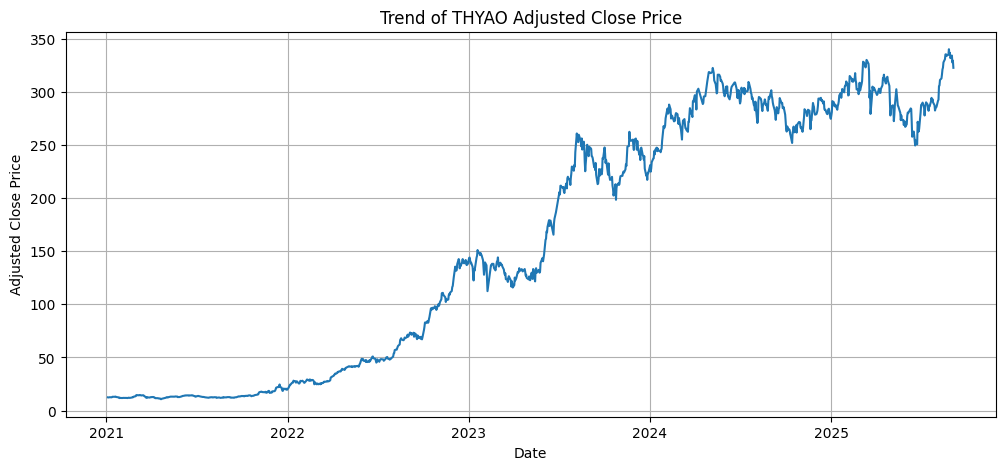

In [ ]:
## Visualisasi Time Series Plot: Harga Adjusted Close
plt.figure(figsize=(12,5))
plt.plot(df['ds'], df['y'])
plt.title("Trend of THYAO Adjusted Close Price")
plt.xlabel("Date")
plt.ylabel("Adjusted Close Price")
plt.grid(True)
plt.show()

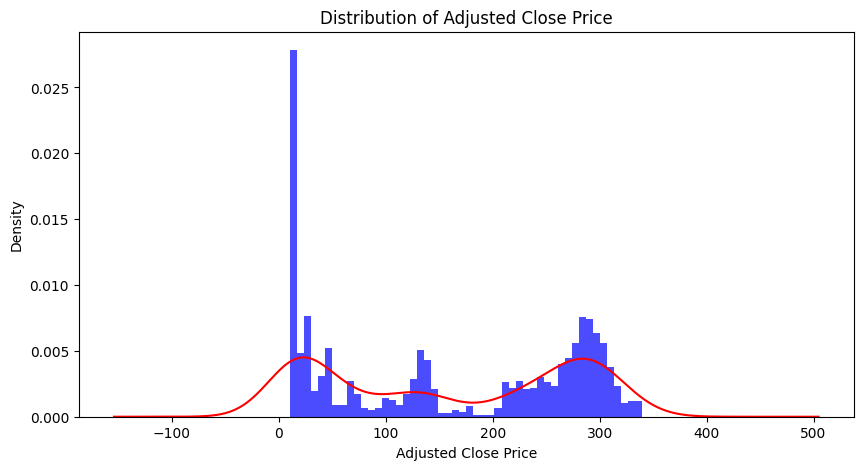

In [ ]:
# Visualisasi Distribusi Harga Adjusted Close
plt.figure(figsize=(10,5))
plt.hist(df['y'], bins=50, alpha=0.7, color='blue', density=True)
df['y'].plot(kind='kde', color='red')
plt.title("Distribution of Adjusted Close Price")
plt.xlabel("Adjusted Close Price")
plt.show()

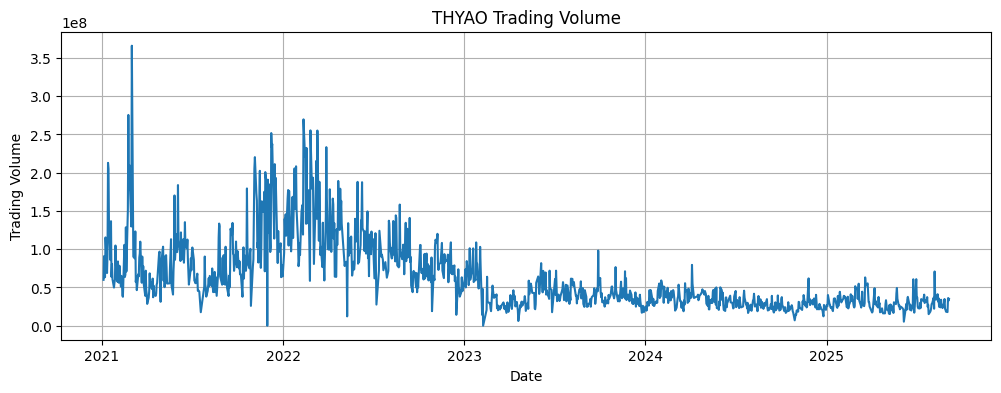

In [ ]:
## Visualisasi Volume Perdagangan
plt.figure(figsize=(12,4))
plt.plot(df['ds'], df['Volume'])
plt.title("THYAO Trading Volume")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.grid(True)
plt.show()

In [ ]:
# Buat lag untuk Adj Close
max_lag = 30
for i in range(1, max_lag + 1):
    df[f'AdjClose_lag_{i}'] = df['y'].shift(i)

# Drop NA setelah lag
df_lag = df.dropna().reset_index(drop=True)

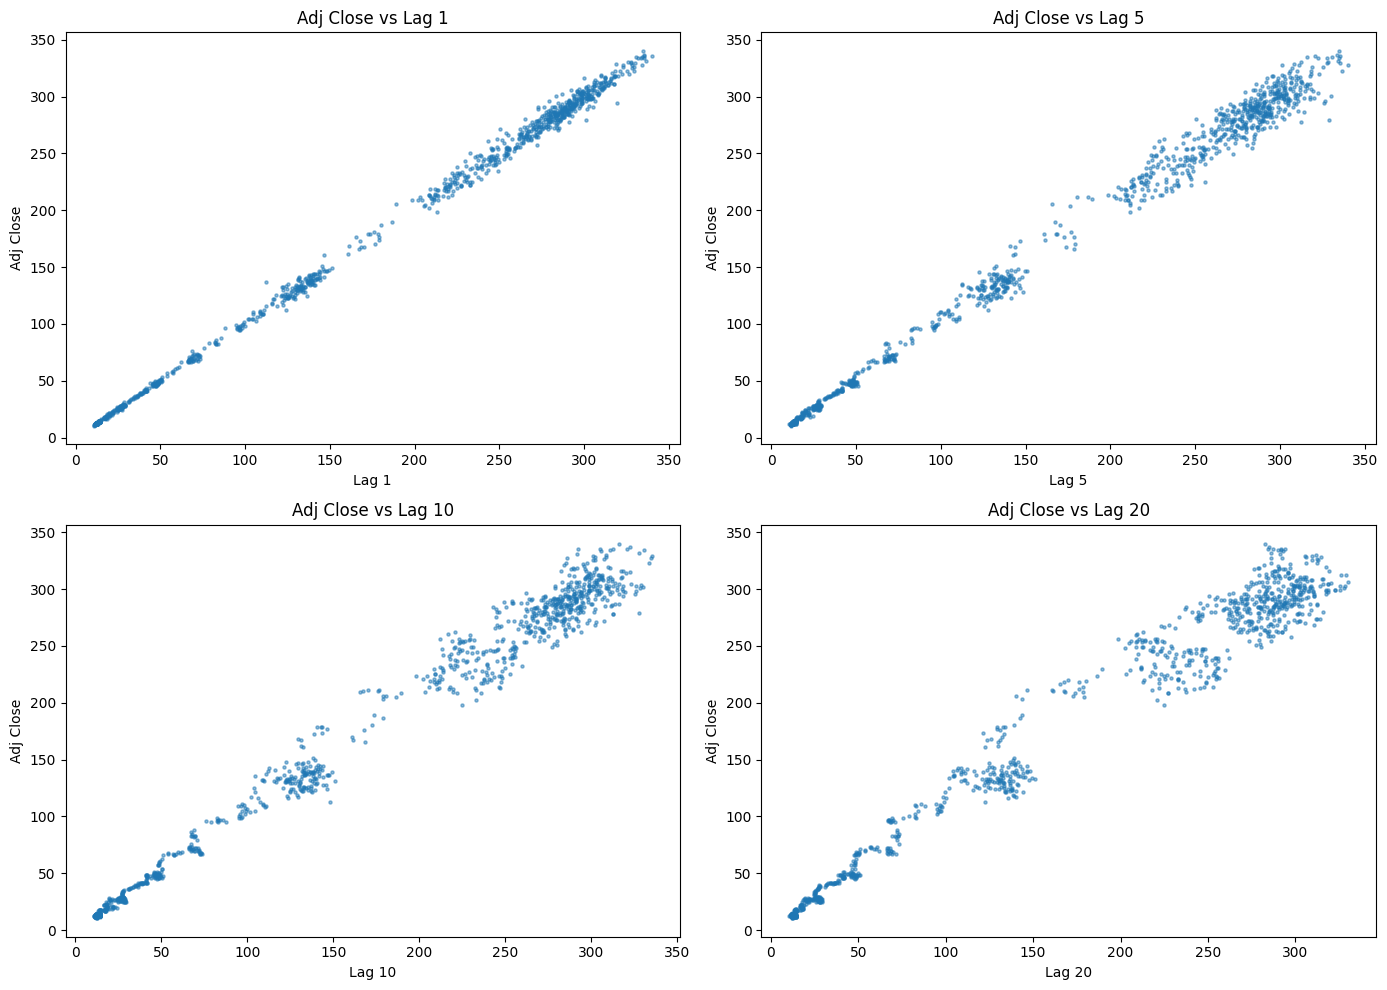

In [ ]:
lags_to_plot = [1, 5, 10, 20]

plt.figure(figsize=(14,10))
for i, lag in enumerate(lags_to_plot, 1):
    plt.subplot(2,2,i)
    plt.scatter(df_lag['AdjClose_lag_' + str(lag)], df_lag['y'], s=5, alpha=0.5)
    plt.title(f"Adj Close vs Lag {lag}")
    plt.xlabel(f"Lag {lag}")
    plt.ylabel("Adj Close")

plt.tight_layout()
plt.show()

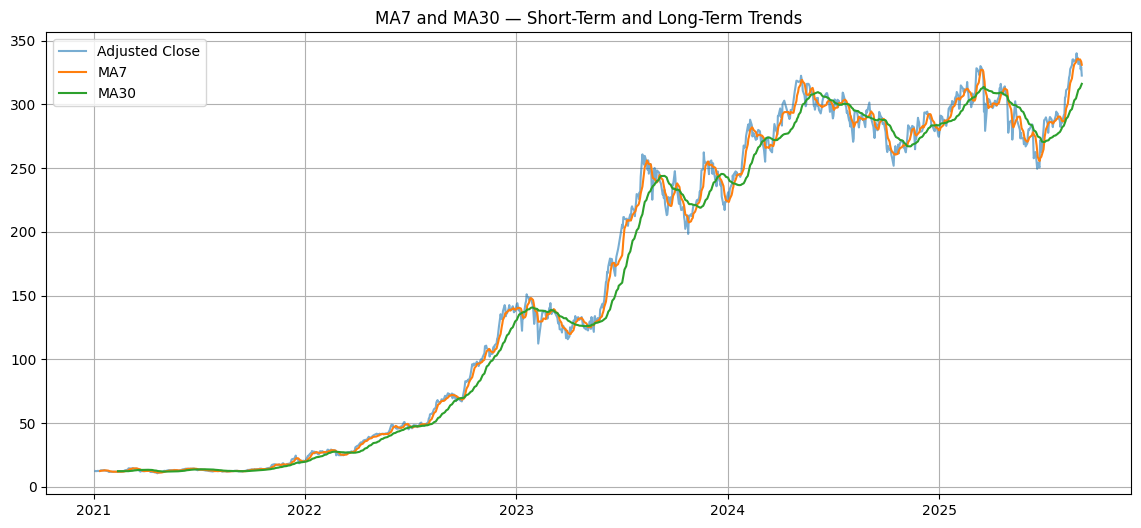

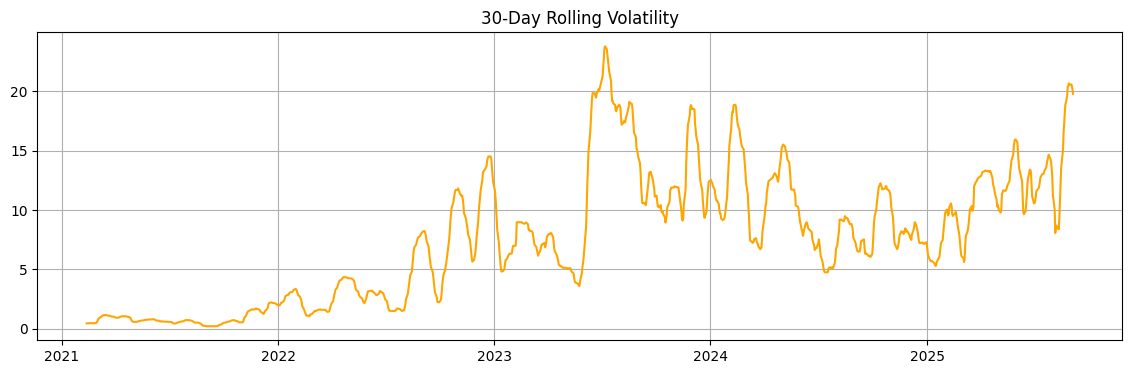

In [ ]:
df['MA7'] = df['y'].rolling(7).mean()
df['MA30'] = df['y'].rolling(30).mean()
df['Volatility30'] = df['y'].rolling(30).std()

plt.figure(figsize=(14,6))
plt.plot(df['ds'], df['y'], label='Adjusted Close', alpha=0.6)
plt.plot(df['ds'], df['MA7'], label='MA7')
plt.plot(df['ds'], df['MA30'], label='MA30')
plt.title("MA7 and MA30 — Short-Term and Long-Term Trends")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(df['ds'], df['Volatility30'], color='orange')
plt.title("30-Day Rolling Volatility")
plt.grid(True)
plt.show()


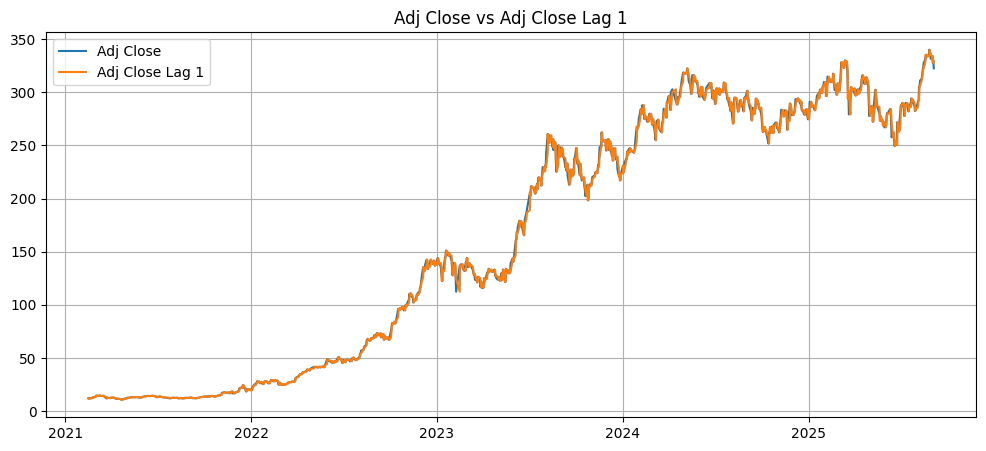

In [ ]:
## visualisasi Lag Adj Close
plt.figure(figsize=(12,5))
plt.plot(df_lag['ds'], df_lag['y'], label='Adj Close')
plt.plot(df_lag['ds'], df_lag['AdjClose_lag_1'], label='Adj Close Lag 1')
plt.title("Adj Close vs Adj Close Lag 1")
plt.legend()
plt.grid(True)
plt.show()



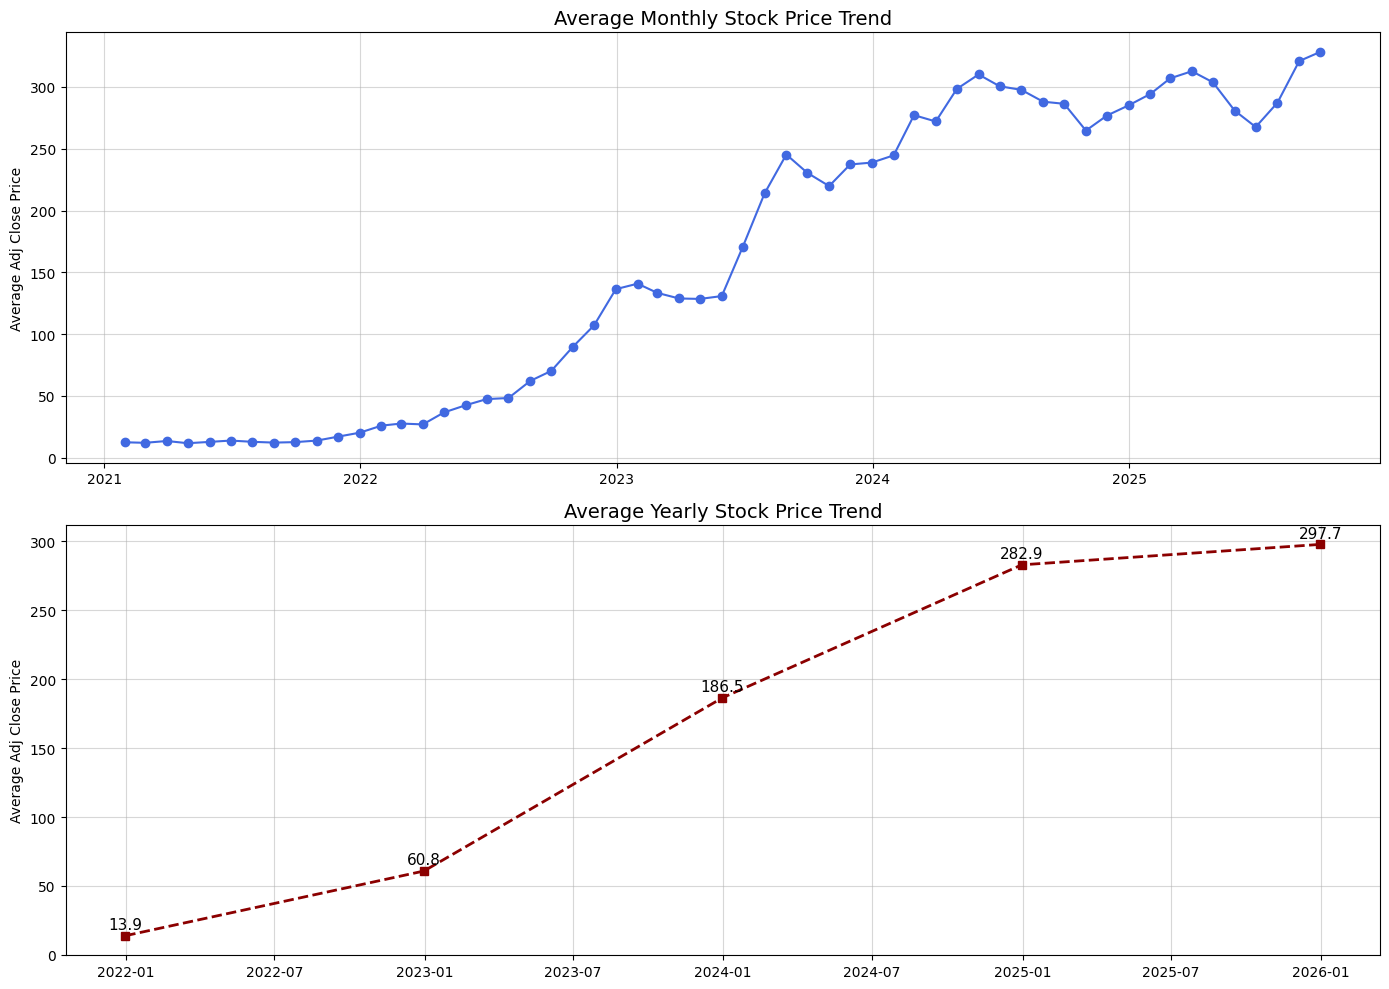

In [ ]:
# Plot per bulan
df_plot = df.copy()
df_plot = df_plot.set_index('ds')

monthly_trend = df_plot['y'].resample('ME').mean()
yearly_trend = df_plot['y'].resample('YE').mean()

# Plotting
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot Bulanan
axes[0].plot(monthly_trend.index, monthly_trend.values, marker='o', linestyle='-', color='royalblue')
axes[0].set_title('Average Monthly Stock Price Trend', fontsize=14)
axes[0].set_ylabel('Average Adj Close Price')
axes[0].grid(True, alpha=0.5)

# Plot Tahunan
axes[1].plot(yearly_trend.index, yearly_trend.values, marker='s', linestyle='--', color='darkred', linewidth=2)
for x, y in zip(yearly_trend.index, yearly_trend.values):
    axes[1].text(x, y+5, f'{y:.1f}', ha='center', fontsize=11) # Menambah label angka

axes[1].set_title('Average Yearly Stock Price Trend', fontsize=14)
axes[1].set_ylabel('Average Adj Close Price')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

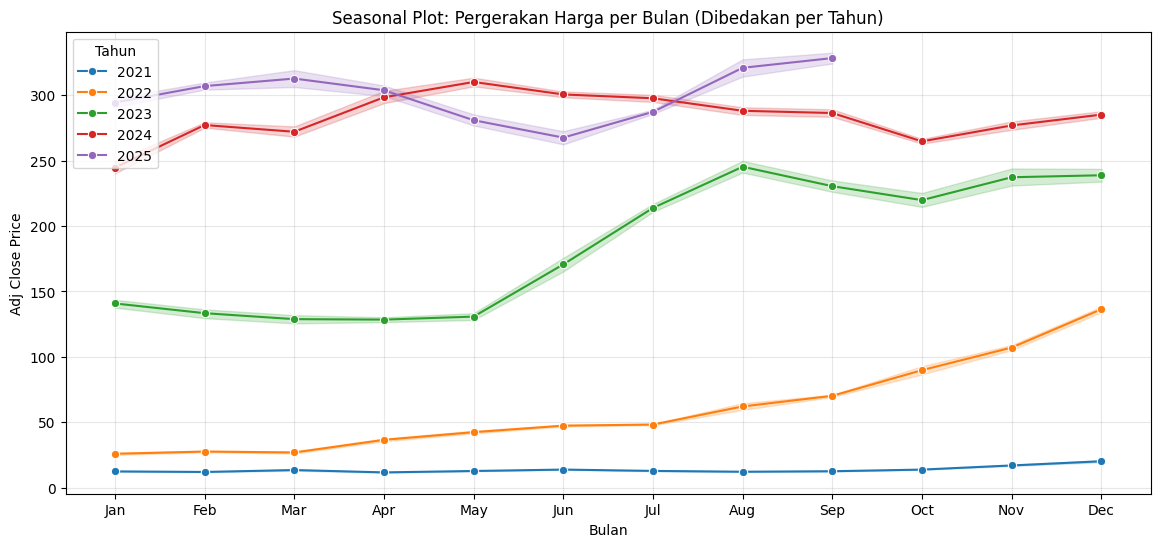

/tmp/ipython-input-3172800892.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='month_name', y='y', palette="Set3")


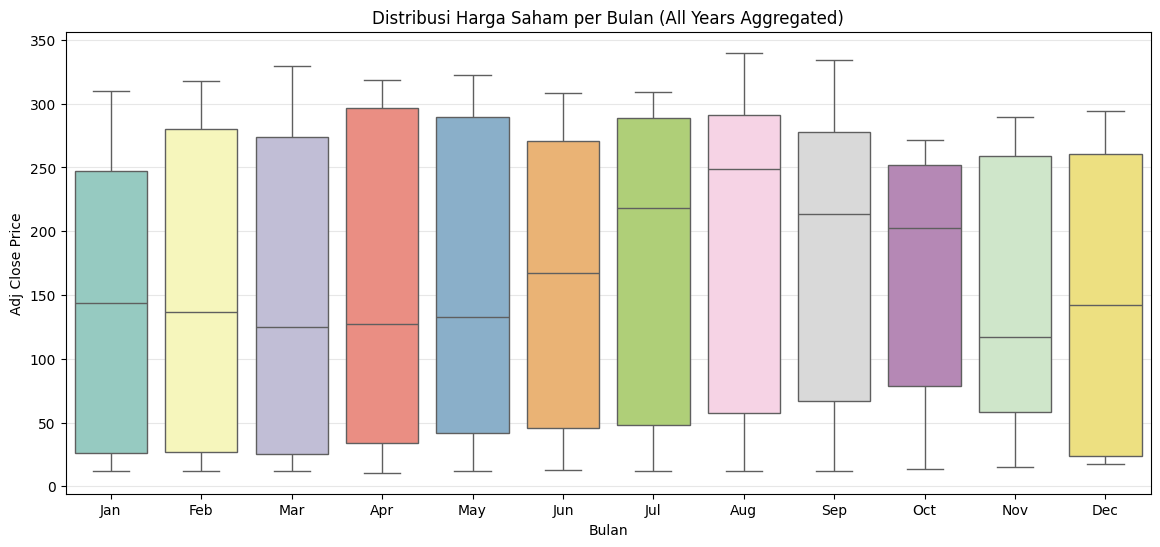

In [ ]:
df['year'] = df['ds'].dt.year
df['month'] = df['ds'].dt.month
df['month_name'] = df['ds'].dt.strftime('%b')

# --- Visualisasi 1: Seasonal Plot (Line Chart per Tahun) ---
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='month_name', y='y', hue='year', palette='tab10', marker='o')

plt.title("Seasonal Plot: Pergerakan Harga per Bulan (Dibedakan per Tahun)")
plt.xlabel("Bulan")
plt.ylabel("Adj Close Price")
plt.legend(title='Tahun', loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

# --- Visualisasi 2: Boxplot Musiman ---
# Boxplot berguna untuk melihat sebaran/distribusi harga di bulan tertentu sepanjang sejarah data
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='month_name', y='y', palette="Set3")

plt.title("Distribusi Harga Saham per Bulan (All Years Aggregated)")
plt.xlabel("Bulan")
plt.ylabel("Adj Close Price")
plt.grid(axis='y', alpha=0.3)
plt.show()

# **Hyperparameter Tuning (TFT)**

Hyperparameter tuning dipakai untuk mencari kombinasi parameter model yang menghasilkan performa prediksi terbaik di data validasi.

<Figure size 1200x400 with 0 Axes>

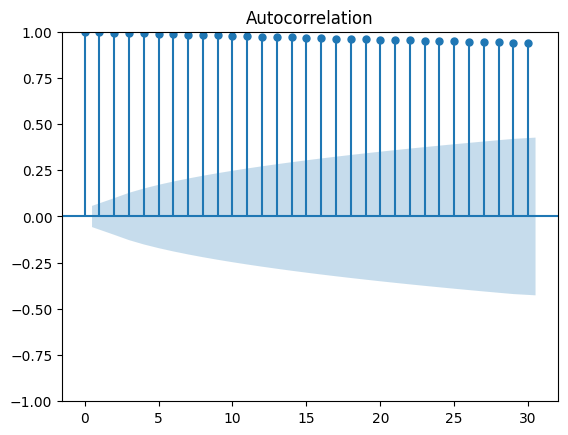

<Figure size 1200x400 with 0 Axes>

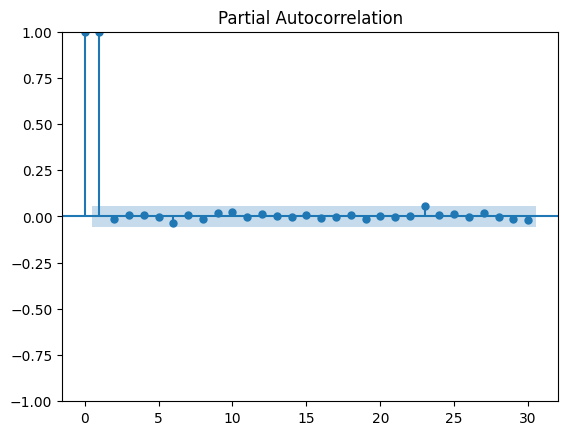

In [ ]:
# Visualisasi ACF dan PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.figure(figsize=(12,4))
plot_acf(df['y'], lags=30)
plt.show()

plt.figure(figsize=(12,4))
plot_pacf(df['y'], lags=30, method='ywm')
plt.show()

- Berdasarkan plot ACF, terlihat bahwa autokorelasi tetap tinggi hingga sekitar lag 20–30, yang menunjukkan adanya ketergantungan jangka menengah pada data harga saham.
Sementara itu, plot PACF menunjukkan spike signifikan pada lag awal, tetapi tidak mengalami cut-off yang jelas pada lag kecil, sehingga window yang terlalu pendek kurang memadai.
- Oleh karena itu, nilai input size 20 dan 30 dipilih sebagai kandidat yang masuk akal untuk menangkap pola historis yang relevan dalam pemodelan time series.

In [ ]:
input_size_candidates = [20, 30]


In [ ]:
# ==========================================
# HYPERPARAMETER TUNING - TFT
# ==========================================
input_sizes = [20, 30]
hidden_sizes = [32, 64]
n_heads = [2, 4]

tuning_results = []

for input_size in input_sizes:
    for hidden_size in hidden_sizes:
        for n_head in n_heads:

            # constraint attention
            if hidden_size % n_head != 0:
                continue

            print(f"Tuning TFT | input={input_size}, hidden={hidden_size}, heads={n_head}")

            model = TFT(
                random_seed=42,
                h=1,
                input_size=input_size,
                hist_exog_list=hist_exog_vars,
                hidden_size=hidden_size,
                n_head=n_head,
                loss=MAE(),
                scaler_type='standard',
                max_steps=300,
                enable_progress_bar=False
            )

            nf = NeuralForecast(models=[model], freq='D')

            cols_to_drop = ['month_name', 'month', 'year']
            df = df.drop(columns=cols_to_drop, errors='ignore')
            df = df.dropna().reset_index(drop=True)
            cv_df = nf.cross_validation(
                df=df,
                val_size=1,
                step_size=1,
                n_windows=100
            )

            valid_idx = ~np.isnan(cv_df['TFT'])

            rmse = np.sqrt(mean_squared_error(
                cv_df.loc[valid_idx, 'y'],
                cv_df.loc[valid_idx, 'TFT']
            ))

            tuning_results.append({
                'input_size': input_size,
                'hidden_size': hidden_size,
                'n_head': n_head,
                'RMSE': rmse
            })


INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Tuning TFT | input=20, hidden=32, heads=2


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                    ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                    │ MAE                      │      0 │ train │     0 │
│ 1 │ padder_train            │ ConstantPad1d            │      0 │ train │     0 │
│ 2 │ scaler                  │ TemporalNorm             │      0 │ train │     0 │
│ 3 │ embedding               │ TFTEmbedding             │    384 │ train │     0 │
│ 4 │ temporal_encoder        │ TemporalCovariateEncoder │ 62.1 K │ train │     0 │
│ 5 │ temporal_fusion_decoder │ TemporalFusionDecoder    │ 17.0 K │ train │     0 │
│ 6 │ output_adapter          │ Linear                   │     33 │ train │     0 │
└───┴─────────────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 79.6 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 79.6 K                                                                                               
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 120                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

...

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=300` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Tuning TFT | input=30, hidden=64, heads=4


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                    ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                    │ MAE                      │      0 │ train │     0 │
│ 1 │ padder_train            │ ConstantPad1d            │      0 │ train │     0 │
│ 2 │ scaler                  │ TemporalNorm             │      0 │ train │     0 │
│ 3 │ embedding               │ TFTEmbedding             │    768 │ train │     0 │
│ 4 │ temporal_encoder        │ TemporalCovariateEncoder │  240 K │ train │     0 │
│ 5 │ temporal_fusion_decoder │ TemporalFusionDecoder    │ 64.8 K │ train │     0 │
│ 6 │ output_adapter          │ Linear                   │     65 │ train │     0 │
└───┴─────────────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 306 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 306 K                                                                                                
Total estimated model params size (MB): 1                                                                          
Modules in train mode: 120                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=300` reached.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


- Kode ini melakukan hyperparameter tuning manual pada model Temporal Fusion Transformer (TFT) dengan mencoba berbagai kombinasi input size, hidden size, dan number of attention heads, lalu mengevaluasi performanya menggunakan RMSE dari rolling cross-validation.
- Model TFT dipilih sebagai contoh karena memiliki arsitektur yang paling kompleks dan fleksibel di antara model yang dibandingkan, khususnya dalam menangani dependensi temporal jangka panjang dan variabel eksogen, sehingga sangat sensitif terhadap pemilihan hyperparameter dan tepat digunakan sebagai studi tuning.

In [ ]:
# ==========================================
# SELECT BEST PARAMETER
# ==========================================
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values('RMSE')
print(tuning_df)


   input_size  hidden_size  n_head      RMSE
0          20           32       2  5.925761
4          30           32       2  6.740942
1          20           32       4  6.993030
7          30           64       4  7.522434
5          30           32       4  7.756258
3          20           64       4  7.910056
2          20           64       2  8.448233
6          30           64       2  8.605338


In [ ]:
best_params = tuning_df.iloc[0]

BEST_INPUT_SIZE = int(best_params['input_size'])
BEST_HIDDEN_SIZE = int(best_params['hidden_size'])
BEST_N_HEAD = int(best_params['n_head'])

print("Best parameters:")
print(BEST_INPUT_SIZE, BEST_HIDDEN_SIZE, BEST_N_HEAD)


Best parameters:
20 32 2


- Hasil tuning menunjukkan bahwa kombinasi input size = 20, hidden size = 32, dan n_head = 4 menghasilkan nilai RMSE terendah, sehingga dipilih sebagai konfigurasi model terbaik.
- Secara umum, hidden size yang lebih kecil (32) memberikan performa lebih baik dibandingkan 64, sementara pemilihan jumlah head dan panjang input window memengaruhi kemampuan model dalam menangkap pola temporal secara optimal.

# **Model Definition**

In [ ]:
models = [
    # 1️⃣ INFORMER (Univariate Baseline)
    Informer(
        random_seed=42,
        h=1,
        input_size=20,
        # hist_exog_list DIHAPUS agar jadi Univariate
        hidden_size=32,
        conv_hidden_size=32,
        n_head=2,
        loss=MAE(),
        scaler_type='standard',
        max_steps=500,
        enable_progress_bar=True
    ),

    # 2️⃣ TFT (Multivariate - Interpretable)
    TFT(
        random_seed=42,
        h=1,
        input_size=20,
        hist_exog_list=hist_exog_vars, # TFT tetap pakai ini
        hidden_size=32,
        n_head=2,
        attn_dropout=0.1,
        loss=MAE(),
        scaler_type='standard',
        max_steps=500,
        enable_progress_bar=True
    ),

    # 3️⃣ N-BEATS (Generic Deep Learning Baseline)
    NBEATS(
        random_seed=42,
        h=1,
        input_size=20,
        # PERBAIKAN DISINI: Ganti Trend/Seasonality jadi Identity
        stack_types=['identity', 'identity'],
        n_blocks=[2, 2],
        mlp_units=[[32, 32], [32, 32]],
        loss=MAE(),
        scaler_type='standard',
        max_steps=500,
        enable_progress_bar=True
    )
]

nf = NeuralForecast(models=models, freq='D')


INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:lightning_fabric.utilities.seed:Seed set to 42


- Kode ini mendefinisikan tiga model deep learning untuk peramalan time series, yaitu Informer, Temporal Fusion Transformer (TFT), dan N-BEATS, yang semuanya menggunakan input window sepanjang 20 periode berdasarkan hasil seleksi dan tuning sebelumnya.
- Model Informer dan TFT menggunakan arsitektur berbasis attention dengan hidden size 32 dan 4 attention heads, sementara TFT secara khusus memanfaatkan variabel eksogen untuk meningkatkan interpretabilitas dan akurasi prediksi.
- Model N-BEATS digunakan sebagai deep learning baseline tanpa mekanisme attention, dengan arsitektur MLP yang lebih sederhana, sehingga memungkinkan perbandingan yang adil antara pendekatan attention-based dan fully-connected dalam memodelkan harga saham.

# **Rolling Cross Validation**

In [ ]:
split_index = int(len(df_lag) * 0.8)
test  = df_lag.iloc[split_index:]

feature_cols = [col for col in df_lag.columns if "AdjClose_lag_" in col]

X_test = test[feature_cols]
y_test = test['y']

print("Test size  :", X_test.shape)

Test size  : (228, 30)


In [ ]:
test_size = 228

print("Running Cross Validation...")
cv_df = nf.cross_validation(
    df=df,
    val_size=10,
    step_size=1,
    n_windows=test_size
)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Running Cross Validation...


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss          │ MAE           │      0 │ train │     0 │
│ 1 │ padder_train  │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler        │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ enc_embedding │ DataEmbedding │     96 │ train │     0 │
│ 4 │ dec_embedding │ DataEmbedding │     96 │ train │     0 │
│ 5 │ encoder       │ TransEncoder  │ 16.2 K │ train │     0 │
│ 6 │ decoder       │ TransDecoder  │ 10.8 K │ train │     0 │
└───┴───────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 27.2 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 27.2 K                                                                                               
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 73                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Trainable params: 13.9 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 13.9 K                                                                                               
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 36                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=500` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

- Potongan kode pertama melakukan pembagian data secara manual dengan skema 80% data sebagai training dan 20% sebagai test, sehingga diperoleh 228 observasi data uji dengan 30 fitur lag sebagai input.
- Nilai test size sebesar 228 ini kemudian digunakan kembali pada proses rolling cross-validation, sehingga jumlah jendela prediksi yang dihasilkan konsisten dengan ukuran data uji yang telah ditentukan.
- Dengan pendekatan ini, evaluasi model dilakukan sepenuhnya pada data out-of-sample, sehingga nilai RMSE dan MAPE yang diperoleh merefleksikan kemampuan generalisasi model secara objektif.

# **Evaluation dan Plot**

In [ ]:
y_true = cv_df['y']

records = []

print("\n=== HASIL EVALUASI ===")
for model in ['Informer', 'TFT', 'NBEATS']:
    valid_idx = ~np.isnan(cv_df[model])

    rmse = np.sqrt(mean_squared_error(
        y_true[valid_idx],
        cv_df.loc[valid_idx, model]
    ))

    mape = mean_absolute_percentage_error(
        y_true[valid_idx],
        cv_df.loc[valid_idx, model]
    ) * 100

    records.append({
        "Model": model,
        "MAPE": mape,
        "RMSE": rmse
    })

    print(f"{model} -> MAPE: {mape:.2f}% | RMSE: {rmse:.4f}")


=== HASIL EVALUASI ===
Informer -> MAPE: 1.55% | RMSE: 6.0910
TFT -> MAPE: 2.08% | RMSE: 7.5920
NBEATS -> MAPE: 1.76% | RMSE: 6.6567


- Hasil evaluasi menunjukkan bahwa Informer memberikan performa terbaik dengan nilai MAPE dan RMSE terendah, sehingga paling akurat dalam memprediksi harga Adjusted Close pada data uji.
- Model N-BEATS berada di urutan kedua, sedangkan TFT menghasilkan error yang relatif lebih tinggi meskipun menggunakan variabel eksogen.

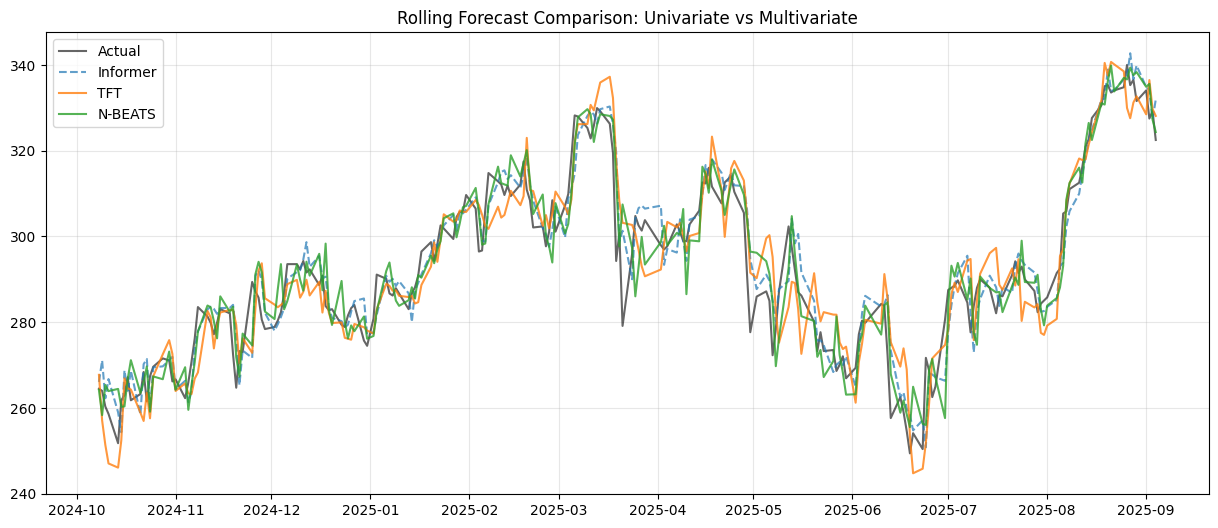

In [ ]:
# Plotting Forecast
plt.figure(figsize=(15,6))
plt.plot(cv_df['ds'], cv_df['y'], label='Actual', color='black', alpha=0.6)
plt.plot(cv_df['ds'], cv_df['Informer'], '--', label='Informer', alpha=0.7)
plt.plot(cv_df['ds'], cv_df['TFT'], label='TFT', alpha=0.8)
plt.plot(cv_df['ds'], cv_df['NBEATS'], label='N-BEATS', alpha=0.8)
plt.title('Rolling Forecast Comparison: Univariate vs Multivariate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

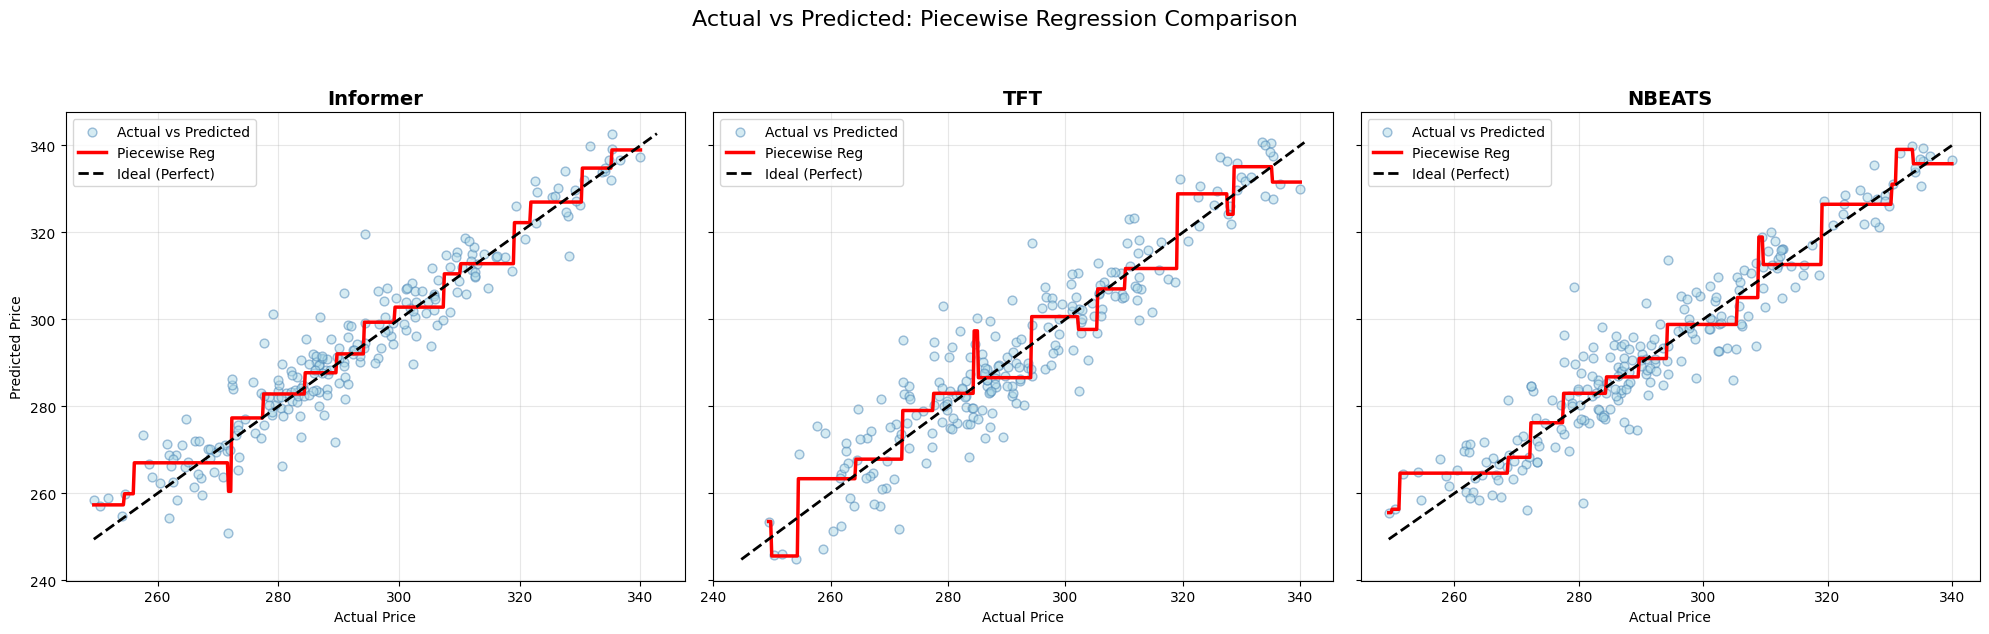

In [ ]:
model_names = ['Informer', 'TFT', 'NBEATS']

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for i, model in enumerate(model_names):
    ax = axes[i]

    # 1. Ambil data (Filter NaN)
    valid_idx = ~np.isnan(cv_df[model])
    y_true = cv_df.loc[valid_idx, 'y'].values.reshape(-1, 1)
    y_pred = cv_df.loc[valid_idx, model].values

    # 2. Buat Model Piecewise (Decision Tree)
    dt_reg = DecisionTreeRegressor(max_depth=4)
    dt_reg.fit(y_true, y_pred)

    X_grid = np.linspace(y_true.min(), y_true.max(), 500).reshape(-1, 1)
    y_grid_pred = dt_reg.predict(X_grid)

    # 3. Plotting
    # A. Scatter Plot (Titik Biru)
    ax.scatter(y_true, y_pred, alpha=0.5, color='lightblue', edgecolors='steelblue', s=40,
               label='Actual vs Predicted')

    # B. Piecewise Regression Line (Garis Merah)
    ax.plot(X_grid, y_grid_pred, color='red', linewidth=2.5, label='Piecewise Reg')

    # C. Ideal Line (Garis Putus-putus Hitam)
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Ideal (Perfect)')


    ax.set_title(f"{model}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Actual Price")
    if i == 0:
        ax.set_ylabel("Predicted Price")

    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left', frameon=True)

plt.suptitle("Actual vs Predicted: Piecewise Regression Comparison", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
# ===============================
# RANKING MODEL
# MAPE (utama), RMSE (pendukung)
# ===============================
result_df = pd.DataFrame(records)

ranking = result_df.sort_values(
    by=["MAPE", "RMSE"],  # MAPE prioritas, RMSE validasi
    ascending=[True, True]
).reset_index(drop=True)

best_model = ranking.loc[0]

print("\n=== MODEL TERBAIK ===")
print(f"Model : {best_model['Model']}")
print(f"MAPE  : {best_model['MAPE']:.2f}%")
print(f"RMSE  : {best_model['RMSE']:.4f}")


=== MODEL TERBAIK ===
Model : Informer
MAPE  : 1.55%
RMSE  : 6.0910


Berdasarkan perankingan dengan MAPE sebagai kriteria utama dan RMSE sebagai pendukung, model Informer terpilih sebagai model terbaik karena menghasilkan kesalahan prediksi paling rendah.

# **Ablation Study (Post-Hoc for TFT)**

- Ablation study dilakukan secara post-hoc pada model TFT karena arsitektur TFT memang dirancang untuk mengakomodasi dan menginterpretasikan pengaruh variabel eksogen, sehingga analisis kontribusi fitur menjadi relevan dan bermakna.
- Pemilihan TFT bukan karena nilai error-nya paling tinggi, melainkan karena Informer dan N-BEATS bersifat univariat atau kurang interpretatif, sehingga post-hoc feature importance tidak dapat diterapkan secara langsung atau tidak memberikan insight yang sebanding.

In [ ]:
def calculate_ablation(nf_model, df_full, features, target_model='TFT'):
    subset = df_full.tail(100).reset_index(drop=True)

    base_preds = nf_model.predict(subset)
    preds_len = len(base_preds)

    y_subset = subset['y'].tail(preds_len).values
    base_yhat = base_preds[target_model].values
    base_mae = np.mean(np.abs(y_subset - base_yhat))

    importance = {}
    for f in features:
        temp = subset.copy()
        # MASKING
        temp[f] = temp[f].mean()

        new_preds = nf_model.predict(temp)
        new_yhat = new_preds[target_model].values
        new_mae = np.mean(np.abs(y_subset - new_yhat))

        importance[f] = new_mae - base_mae

    return importance

- MAE digunakan dalam ablation study karena mengukur dampak kesalahan secara langsung dan stabil dalam satuan yang sama dengan target, sehingga perubahan error akibat pemaskingan fitur dapat diinterpretasikan dengan jelas.
- MAPE kurang sesuai karena sensitif terhadap nilai aktual yang kecil, sedangkan RMSE memberi penalti berlebih pada error ekstrem sehingga dapat menutupi pengaruh fitur secara individual dalam analisis kontribusi.

In [ ]:
# Jalankan Ablation
print("\nMenghitung Feature Importance...")
imp_scores = calculate_ablation(nf, df, hist_exog_vars)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()


Menghitung Feature Importance...


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

...

Output()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

- Kode ini melakukan ablation study pasca-pelatihan (post-hoc) pada model TFT dengan cara memasking satu variabel eksogen pada satu waktu untuk mengukur peningkatan error MAE, sehingga dapat menilai kontribusi masing-masing fitur terhadap performa prediksi.
- Semakin besar kenaikan MAE setelah suatu fitur dimasking, semakin penting peran fitur tersebut dalam membantu model TFT memprediksi harga saham.

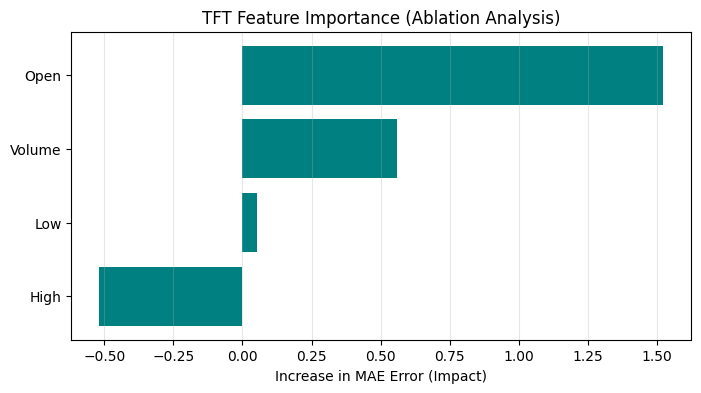

In [ ]:
# Sorting biar grafik rapi
sorted_scores = dict(sorted(imp_scores.items(), key=lambda item: item[1]))

plt.figure(figsize=(8,4))
plt.barh(list(sorted_scores.keys()), list(sorted_scores.values()), color='teal')
plt.title('TFT Feature Importance (Ablation Analysis)')
plt.xlabel('Increase in MAE Error (Impact)')
plt.grid(axis='x', alpha=0.3)
plt.show()